In [1]:
%pip install pandas matplotlib numpy 
%pip install openpyxl 


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import matplotlib.gridspec as gridspec 

In [3]:
df = pd.read_excel("malic_acid_fermentation.xlsx")
df

,Unnamed: 0,{Batch Information},Time,Glucose [g/L],Malic acid [g/L],Succinic acid [g/L],CDW [g/L]
0,V9PB0105.spc#1,"F1, Training, Pulsed batch, manual feed",0.000000,99.485333,0.0000,0.000000,0.062361
1,V9PB0106.spc#1,"F1, Training, Pulsed batch, manual feed",0.166667,98.160000,0.0000,0.000000,0.154560
2,V9PB0107.spc#1,"F1, Training, Pulsed batch, manual feed",0.333333,NaN,NaN,NaN,NaN
3,V9PB0108.spc#1,"F1, Training, Pulsed batch, manual feed",0.500000,NaN,NaN,NaN,NaN
4,V9PB0109.spc#1,"F1, Training, Pulsed batch, manual feed",0.666389,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
749,V9PB0854.spc#1,"F1, Training, Pulsed batch, manual feed",124.831667,NaN,NaN,NaN,NaN
750,V9PB0855.spc#1,"F1, Training, Pulsed batch, manual feed",124.998333,0.000000,109.7735,19.000167,1.643675
751,V9PB0856.spc#1,"F1, Training, Pulsed batch, manual feed",125.165000,NaN,NaN,NaN,NaN
752,V9PB0857.spc#1,"F1, Training, Pulsed batch, manual feed",125.331667,NaN,NaN,NaN,NaN


In [4]:
#exploring null values 

df.isna().sum()

Unnamed: 0               0
{Batch Information}      0
Time                     0
Glucose [g/L]          716
Malic acid [g/L]       716
Succinic acid [g/L]    716
CDW [g/L]              716
dtype: int64

In [5]:
#exploring dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 754 entries, 0 to 753
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           754 non-null    str    
 1   {Batch Information}  754 non-null    str    
 2   Time                 754 non-null    float64
 3   Glucose [g/L]        38 non-null     float64
 4   Malic acid [g/L]     38 non-null     float64
 5   Succinic acid [g/L]  38 non-null     float64
 6   CDW [g/L]            38 non-null     float64
dtypes: float64(5), str(2)
memory usage: 41.4 KB


In [6]:
#exploring dataset
df.describe() 

,Time,Glucose [g/L],Malic acid [g/L],Succinic acid [g/L],CDW [g/L]
count,754.000000,38.000000,38.000000,38.000000,38.000000
mean,62.748658,42.626398,43.892176,5.811390,0.652805
std,36.300435,29.076920,33.100934,5.075316,0.711489
min,0.000000,0.000000,0.000000,0.000000,0.062361
25%,31.373333,25.706475,16.393375,1.524000,0.289561
50%,62.748333,33.115667,56.816333,7.077750,0.415989
75%,94.123333,59.825125,64.120167,8.326917,0.745609
max,125.498333,99.485333,109.773500,19.000167,3.395176


In [7]:
#duplicated data

df.duplicated().sum()

np.int64(0)

In [8]:
#cleaning data step 

cleaned_df = df.dropna()


In [9]:
cleaned_df.isna().sum() 

Unnamed: 0             0
{Batch Information}    0
Time                   0
Glucose [g/L]          0
Malic acid [g/L]       0
Succinic acid [g/L]    0
CDW [g/L]              0
dtype: int64

In [10]:
#extracting numeric features

df = cleaned_df.loc[:, ["Time", "Glucose [g/L]", "Malic acid [g/L]", "Succinic acid [g/L]", "CDW [g/L]"]]
df 

,Time,Glucose [g/L],Malic acid [g/L],Succinic acid [g/L],CDW [g/L]
0,0.000000,99.485333,0.000000,0.000000,0.062361
1,0.166667,98.160000,0.000000,0.000000,0.154560
12,2.000000,97.166333,0.000000,0.000000,0.084984
24,4.000000,95.085333,0.000000,0.000000,0.102740
36,6.000000,96.091000,0.000000,0.000000,0.141421
47,7.833333,94.591667,0.000000,0.000000,0.412984
138,23.000000,34.031867,10.634467,1.007067,0.285774
144,24.000000,27.507933,11.372000,1.089933,0.418994
150,24.998333,24.597633,14.360967,1.301700,0.418994
155,25.831667,20.485867,16.319533,1.507333,0.389444


In [11]:
#exploring correlation between variables 

df.corr()

,Time,Glucose [g/L],Malic acid [g/L],Succinic acid [g/L],CDW [g/L]
Time,1.000000,-0.595463,0.964740,0.976783,0.553865
Glucose [g/L],-0.595463,1.000000,-0.514727,-0.482985,-0.318179
Malic acid [g/L],0.964740,-0.514727,1.000000,0.987942,0.544134
Succinic acid [g/L],0.976783,-0.482985,0.987942,1.000000,0.558374
CDW [g/L],0.553865,-0.318179,0.544134,0.558374,1.000000


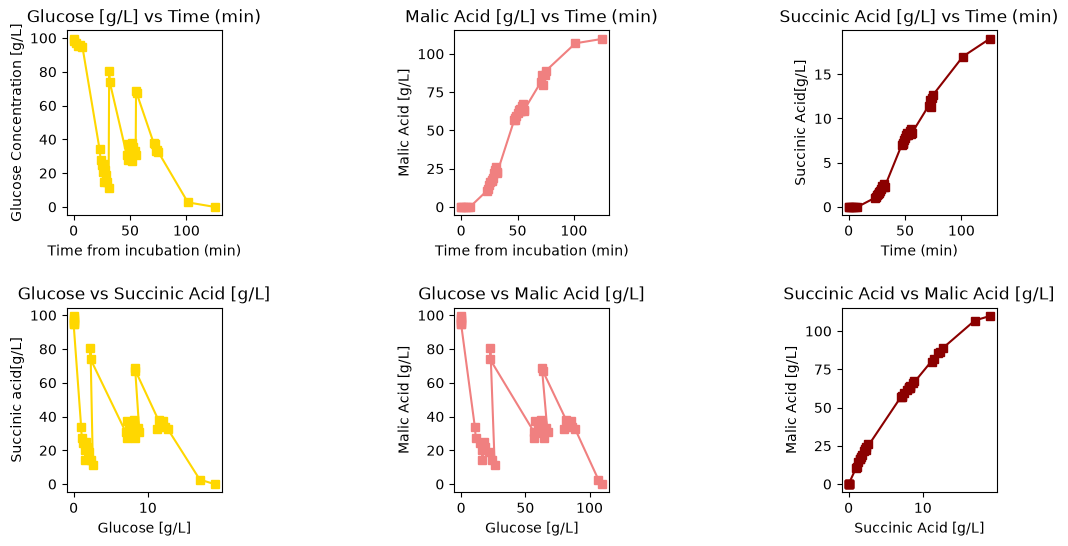

In [12]:
gs = gridspec.GridSpec(2, 3, wspace=1.5, hspace=0.5, width_ratios = [10, 10, 10], height_ratios = [1, 1])

fig = plt.figure(figsize=(12, 6))

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(df["Time"], df["Glucose [g/L]"], marker="s", color="gold", label="Glucose [g/L]")
ax1.set_title("Glucose [g/L] vs Time (min)")
ax1.set_xlabel("Time from incubation (min)")
ax1.set_ylabel("Glucose Concentration [g/L]")



ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(df["Time"], df["Malic acid [g/L]"], marker="s", color="lightcoral", label="Malic Acid [g/L]")
ax2.set_title("Malic Acid [g/L] vs Time (min)")
ax2.set_xlabel("Time from incubation (min)")
ax2.set_ylabel("Malic Acid [g/L]")




ax3 = fig.add_subplot(gs[0, 2])
ax3.plot(df["Time"], df["Succinic acid [g/L]"], marker="s", color="darkred", label="Succinic Acid [g/L]")
ax3.set_title("Succinic Acid [g/L] vs Time (min)")
ax3.set_xlabel("Time (min)")
ax3.set_ylabel("Succinic Acid[g/L]")



ax4 =  fig.add_subplot(gs[1, 0])
ax4.plot(df["Succinic acid [g/L]"], df["Glucose [g/L]"], marker="s", color="gold", label="Glucose vs Succinic Acid [g/L]")
ax4.set_title("Glucose vs Succinic Acid [g/L]")
ax4.set_xlabel("Glucose [g/L]")
ax4.set_ylabel("Succinic acid[g/L]")



ax5 = fig.add_subplot(gs[1, 1])
ax5.plot(df["Malic acid [g/L]"], df["Glucose [g/L]"], marker="s", color="lightcoral", label="Malic acid vs glucose [g/L]")
ax5.set_title("Glucose vs Malic Acid [g/L]")
ax5.set_xlabel("Glucose [g/L]")
ax5.set_ylabel("Malic Acid [g/L]")




ax6 = fig.add_subplot(gs[1, 2])
ax6.plot(df["Succinic acid [g/L]"], df["Malic acid [g/L]"], marker="s", color="darkred", label="Succinic Acid vs Malic Acid [g/L]")
ax6.set_title("Succinic Acid vs Malic Acid [g/L]")
ax6.set_xlabel("Succinic Acid [g/L]")
ax6.set_ylabel("Malic Acid [g/L]")

plt.show()
